# Tourism Data Preprocessing

This notebook describes the preprocessing steps applied to the tourism dataset obtained from the Swedish Agency for Economic and Regional Growth (Tillväxtverket).

The dataset contains monthly guest-night statistics for registered accommodation establishments in Swedish municipalities between January 2008 and December 2025.

This follows the same preprocessing steps as "tourism_guest_nights_detailed.ipynb" but is applied on tourism_guest_nights instead

In [30]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt


### Define the dataset location

In [31]:

FILE_PATH = (
    Path.cwd()
    / "tourism_guest_nights.xlsx"
)

OUTPUT_PATH = Path.cwd() / "processed_tourism_totals.csv"

print("Input file:", FILE_PATH)
print("File exists:", FILE_PATH.exists())


Input file: c:\Users\kimwo\software engineering\year 5\LP1\4DT911 - Project\4dt911-vis-project-research\notebooks\data_preprocessing\tourism_guest_nights.xlsx
File exists: True


### Load the dataset

In [32]:

df = pd.read_excel(
    FILE_PATH,
    header=2,
    dtype={"Kommun Kod": "string"}
)

df.head(10)


c:\Users\kimwo\AppData\Local\Programs\Python\Python313\Lib\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


,Antal gästnätter,Kommun Kod,Kommun,2008-01,2008-02,2008-03,2008-04,2008-05,2008-06,2008-07,...,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12
0,Nivå: Kommun,<NA>,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,0117,Österåker,3008.0,2918.0,2932.0,4705.0,7578.0,9660.0,10986.0,...,NaN,2893.0,5810.0,4515.0,6757.0,9063.0,6506.0,NaN,NaN,NaN
2,NaN,0120,Värmdö,5010.0,5974.0,5191.0,10049.0,17811.0,19493.0,29227.0,...,7677.0,13369.0,22035.0,24571.0,43730.0,42204.0,22183.0,18407.0,11508.0,11109.0
3,NaN,0123,Järfälla,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,0125,Ekerö,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,6177.0,4675.0,8581.0,8377.0,7561.0,8191.0,10558.0,10251.0,8805.0,6669.0
5,NaN,0126,Huddinge,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,23170.0,24788.0,32994.0,29084.0,34166.0,36612.0,27149.0,29730.0,23413.0,17485.0
6,NaN,0127,Botkyrka,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,NaN,0136,Haninge,6080.0,7555.0,7647.0,10171.0,18477.0,23394.0,36707.0,...,8305.0,11953.0,17497.0,24645.0,40958.0,30758.0,19774.0,13935.0,11298.0,10528.0
8,NaN,0139,Upplands-Bro,5096.0,4302.0,3363.0,8002.0,8661.0,7046.0,NaN,...,3544.0,3287.0,7156.0,5246.0,3933.0,7432.0,8288.0,5939.0,6359.0,3235.0
9,NaN,0160,Täby,7827.0,7213.0,7266.0,9470.0,11893.0,9563.0,NaN,...,10492.0,9828.0,11727.0,11401.0,NaN,14950.0,10564.0,11820.0,10102.0,8179.0


In [33]:

print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes.value_counts())

print("\nFirst observations:")
display(df.head())


Dataset shape: (262, 219)

Column names:
['Antal gästnätter', 'Kommun Kod', 'Kommun', '2008-01', '2008-02', '2008-03', '2008-04', '2008-05', '2008-06', '2008-07', '2008-08', '2008-09', '2008-10', '2008-11', '2008-12', '2009-01', '2009-02', '2009-03', '2009-04', '2009-05', '2009-06', '2009-07', '2009-08', '2009-09', '2009-10', '2009-11', '2009-12', '2010-01', '2010-02', '2010-03', '2010-04', '2010-05', '2010-06', '2010-07', '2010-08', '2010-09', '2010-10', '2010-11', '2010-12', '2011-01', '2011-02', '2011-03', '2011-04', '2011-05', '2011-06', '2011-07', '2011-08', '2011-09', '2011-10', '2011-11', '2011-12', '2012-01', '2012-02', '2012-03', '2012-04', '2012-05', '2012-06', '2012-07', '2012-08', '2012-09', '2012-10', '2012-11', '2012-12', '2013-01', '2013-02', '2013-03', '2013-04', '2013-05', '2013-06', '2013-07', '2013-08', '2013-09', '2013-10', '2013-11', '2013-12', '2014-01', '2014-02', '2014-03', '2014-04', '2014-05', '2014-06', '2014-07', '2014-08', '2014-09', '2014-10', '2014-11', '

,Antal gästnätter,Kommun Kod,Kommun,2008-01,2008-02,2008-03,2008-04,2008-05,2008-06,2008-07,...,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12
0,Nivå: Kommun,<NA>,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,0117,Österåker,3008.0,2918.0,2932.0,4705.0,7578.0,9660.0,10986.0,...,NaN,2893.0,5810.0,4515.0,6757.0,9063.0,6506.0,NaN,NaN,NaN
2,NaN,0120,Värmdö,5010.0,5974.0,5191.0,10049.0,17811.0,19493.0,29227.0,...,7677.0,13369.0,22035.0,24571.0,43730.0,42204.0,22183.0,18407.0,11508.0,11109.0
3,NaN,0123,Järfälla,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,0125,Ekerö,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,6177.0,4675.0,8581.0,8377.0,7561.0,8191.0,10558.0,10251.0,8805.0,6669.0


In [34]:

# Identify monthly columns
month_columns = [
    col for col in df.columns
    if isinstance(col, str)
    and pd.notna(
        pd.to_datetime(
            col, format="%Y-%m", errors="coerce"
        )
    )
]

# Keep only relevant columns
columns_to_keep = [
    "Kommun Kod",
    "Kommun"
] + month_columns

df = df[columns_to_keep].copy()

# Standardize municipality codes
df["Kommun Kod"] = (
    df["Kommun Kod"].str.strip().str.zfill(4)
)

df = df[
    df["Kommun Kod"].str.fullmatch(r"\d{4}", na=False)
].copy()

print("Remaining rows:", len(df))
print("Monthly columns:", len(month_columns))


Remaining rows: 259
Monthly columns: 216


### Filter stockholm county

In [35]:

# Filter using municipality codes
df = df[
    df["Kommun Kod"].str.startswith("01", na=False)
].copy()

print("Rows after filtering:", len(df))

print(
    "Number of municipalities:",
    df["Kommun Kod"].nunique()
)

print("\nMunicipalities:")
display(
    df[["Kommun Kod", "Kommun"]]
    .drop_duplicates()
    .sort_values("Kommun")
)


Rows after filtering: 19
Number of municipalities: 19

Municipalities:


,Kommun Kod,Kommun
6,0127,Botkyrka
4,0125,Ekerö
7,0136,Haninge
5,0126,Huddinge
3,0123,Järfälla
15,0186,Lidingö
13,0182,Nacka
17,0188,Norrtälje
19,0192,Nynäshamn
18,0191,Sigtuna


In [36]:
print("Missing municipality identifiers:")
print(df[["Kommun Kod", "Kommun"]].isna().sum())

print("\nDuplicate municipality codes:")
print(df.duplicated(subset=["Kommun Kod"]).sum())

Missing municipality identifiers:
Kommun Kod    0
Kommun        0
dtype: int64

Duplicate municipality codes:
0


## Restructuring the Dataset

The original dataset uses a wide format, where each month is represented by a separate column.

To simplify data analysis, the dataset is transformed into long format, where each row represents one municipality, accommodation type and month.

This transformation allows observations to be grouped, filtered and compared across both time and geographic locations.

The transformation is performed using the pandas `melt()` function.

In [37]:
df = df.melt(
    id_vars=[
        "Kommun Kod",
        "Kommun"
    ],
    value_vars=month_columns,
    var_name="date",
    value_name="guest_nights"
)

print("New dataset shape:", df.shape)

df.head(10)

New dataset shape: (4104, 4)


,Kommun Kod,Kommun,date,guest_nights
0,0117,Österåker,2008-01,3008.0
1,0120,Värmdö,2008-01,5010.0
2,0123,Järfälla,2008-01,NaN
3,0125,Ekerö,2008-01,NaN
4,0126,Huddinge,2008-01,NaN
5,0127,Botkyrka,2008-01,NaN
6,0136,Haninge,2008-01,6080.0
7,0139,Upplands-Bro,2008-01,5096.0
8,0160,Täby,2008-01,7827.0
9,0163,Sollentuna,2008-01,11215.0


In [38]:
df = df.rename(columns={
    "Kommun Kod": "municipality_code",
    "Kommun": "municipality"
})

df.head()

,municipality_code,municipality,date,guest_nights
0,0117,Österåker,2008-01,3008.0
1,0120,Värmdö,2008-01,5010.0
2,0123,Järfälla,2008-01,NaN
3,0125,Ekerö,2008-01,NaN
4,0126,Huddinge,2008-01,NaN


In [39]:

# Convert dates to datetime
df["date"] = pd.to_datetime(
    df["date"],
    format="%Y-%m",
    errors="raise"
)

# Identify unexpected non-numeric observations
numeric_guest_nights = pd.to_numeric(
    df["guest_nights"],
    errors="coerce"
)

invalid_numeric = (
    df["guest_nights"].notna()
    & numeric_guest_nights.isna()
)

print(
    "Unexpected non-numeric guest-night values:",
    invalid_numeric.sum()
)

if invalid_numeric.any():
    display(df.loc[invalid_numeric])

# Convert guest nights to numeric
df["guest_nights"] = numeric_guest_nights

print("\nUpdated data types:")
print(df.dtypes)


Unexpected non-numeric guest-night values: 0

Updated data types:
municipality_code    string[python]
municipality                 object
date                 datetime64[ns]
guest_nights                float64
dtype: object


## Missing Value Analysis

The dataset contains missing monthly observations for some municipalities and accommodation types.

Missing observations may represent unavailable, unreported or confidentiality-affected data. Their exact meaning cannot be determined solely from the spreadsheet.

Therefore, missing guest-night values are preserved as `NaN` rather than being replaced with zero.

Replacing missing values with zero could incorrectly suggest that no visitors stayed in an accommodation category during a particular month.

The number and distribution of missing observations are investigated before proceeding with further analysis.

In [40]:
missing_values = df.isna().sum()

print("Missing values:")
print(missing_values)

missing_count = df["guest_nights"].isna().sum()

missing_percentage = (
    missing_count / len(df) * 100
)

print(f"\nMissing guest-night values: {missing_count}")
print(f"Missing percentage: {missing_percentage:.2f}%")

missing_by_municipality = (
    df.groupby("municipality")["guest_nights"]
    .agg(total="size", available="count")
)

missing_by_municipality["missing"] = (
    missing_by_municipality["total"]
    - missing_by_municipality["available"]
)

display(missing_by_municipality)

Missing values:
municipality_code      0
municipality           0
date                   0
guest_nights         593
dtype: int64

Missing guest-night values: 593
Missing percentage: 14.45%


,total,available,missing
municipality,,,
Botkyrka,216,87,129
Ekerö,216,92,124
Haninge,216,216,0
Huddinge,216,179,37
Järfälla,216,3,213
Lidingö,216,216,0
Nacka,216,216,0
Norrtälje,216,216,0
Nynäshamn,216,216,0


### Check for duplicates and invalid values

In [41]:

# Identify duplicate observations
key_columns = [
    "municipality_code",
    "date"
]

duplicates = df.duplicated(
    subset=key_columns,
    keep=False
)

print("Duplicate observations:", duplicates.sum())

if duplicates.any():
    display(
        df.loc[duplicates]
        .sort_values(key_columns)
    )

# Check for negative guest nights
negative_values = df["guest_nights"] < 0

print(
    "Negative guest-night observations:",
    negative_values.sum()
)

# Check the date range
print("Earliest date:", df["date"].min())
print("Latest date:", df["date"].max())

# Validate important assumptions
assert not duplicates.any(), "Duplicate keys detected"
assert not negative_values.any(), "Negative guest nights detected"


Duplicate observations: 0
Negative guest-night observations: 0
Earliest date: 2008-01-01 00:00:00
Latest date: 2025-12-01 00:00:00


In [42]:

# Extract year and month
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month

# Define seasons using a consistent month mapping
season_mapping = {
    12: "Winter", 1: "Winter", 2: "Winter",
    3: "Spring", 4: "Spring", 5: "Spring",
    6: "Summer", 7: "Summer", 8: "Summer",
    9: "Autumn", 10: "Autumn", 11: "Autumn"
}

df["season"] = df["month"].map(season_mapping)

df[
    [
        "municipality",
        "date",
        "year",
        "month",
        "season",
        "guest_nights"
    ]
].head()


,municipality,date,year,month,season,guest_nights
0,Österåker,2008-01-01,2008,1,Winter,3008.0
1,Värmdö,2008-01-01,2008,1,Winter,5010.0
2,Järfälla,2008-01-01,2008,1,Winter,NaN
3,Ekerö,2008-01-01,2008,1,Winter,NaN
4,Huddinge,2008-01-01,2008,1,Winter,NaN


### Inspect completeness across municipalities

In [43]:

# Calculate availability of guest-night observations
municipality_completeness = (
    df.groupby("municipality")["guest_nights"]
    .agg(
        total_observations="size",
        available_observations="count"
    )
)

municipality_completeness["completeness_pct"] = (
    municipality_completeness["available_observations"]
    / municipality_completeness["total_observations"]
    * 100
)

display(
    municipality_completeness.sort_values(
        "completeness_pct", ascending=False
    )
)


,total_observations,available_observations,completeness_pct
municipality,,,
Sigtuna,216,216,100.000000
Södertälje,216,216,100.000000
Haninge,216,216,100.000000
Värmdö,216,216,100.000000
Vaxholm,216,216,100.000000
Lidingö,216,216,100.000000
Nacka,216,216,100.000000
Norrtälje,216,216,100.000000
Nynäshamn,216,216,100.000000


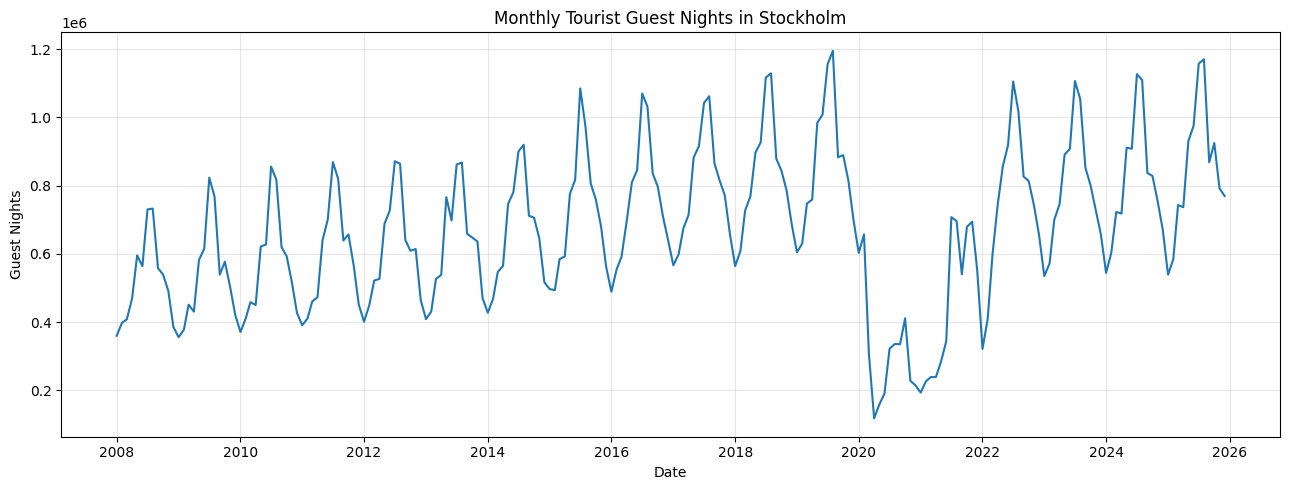

In [44]:
stockholm = df[
    df["municipality"] == "Stockholm"
].sort_values("date")

plt.figure(figsize=(13, 5))

plt.plot(
    stockholm["date"],
    stockholm["guest_nights"]
)

plt.title("Monthly Tourist Guest Nights in Stockholm")
plt.xlabel("Date")
plt.ylabel("Guest Nights")

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Final Dataset

The tourism dataset has been preprocessed through the following operations:

- Removed unnecessary metadata and invalid rows.
- Filtered the dataset to Stockholm County municipalities.
- Reshaped the dataset from wide to long format.
- Renamed variables and accommodation categories to English.
- Converted dates and guest-night values into appropriate data types.
- Investigated missing values and preserved unavailable observations.
- Checked for duplicate observations and invalid numerical values.
- Created additional temporal features for future analysis.

The processed dataset is exported as `processed_tourism_data.csv`.

The resulting dataset can be used for tourism-related visualizations and subsequent integration with the housing market and Airbnb datasets.

**Limitations:** The dataset contains only 19 of Stockholm County's 26 municipalities. Missing observations are preserved, and the confidentiality-protected accommodation category remains identified separately. These limitations must be considered when calculating aggregate tourism statistics.

In [45]:
column_order = [
    "municipality_code",
    "municipality",
    "date",
    "year",
    "month",
    "season",
    "guest_nights"
]

df = df[column_order]

df = df.sort_values(
    ["municipality_code", "date"]
).reset_index(drop=True)

df.to_csv(
    OUTPUT_PATH,
    index=False,
    encoding="utf-8-sig",
    date_format="%Y-%m-%d"
)

print("Processed dataset saved to:", OUTPUT_PATH)
print("Final shape:", df.shape)

df.head(10)

Processed dataset saved to: c:\Users\kimwo\software engineering\year 5\LP1\4DT911 - Project\4dt911-vis-project-research\notebooks\data_preprocessing\processed_tourism_totals.csv
Final shape: (4104, 7)


,municipality_code,municipality,date,year,month,season,guest_nights
0,0117,Österåker,2008-01-01,2008,1,Winter,3008.0
1,0117,Österåker,2008-02-01,2008,2,Winter,2918.0
2,0117,Österåker,2008-03-01,2008,3,Spring,2932.0
3,0117,Österåker,2008-04-01,2008,4,Spring,4705.0
4,0117,Österåker,2008-05-01,2008,5,Spring,7578.0
5,0117,Österåker,2008-06-01,2008,6,Summer,9660.0
6,0117,Österåker,2008-07-01,2008,7,Summer,10986.0
7,0117,Österåker,2008-08-01,2008,8,Summer,10296.0
8,0117,Österåker,2008-09-01,2008,9,Autumn,8631.0
9,0117,Österåker,2008-10-01,2008,10,Autumn,7278.0


In [46]:
processed_df = pd.read_csv(
    OUTPUT_PATH,
    dtype={"municipality_code": "string"},
    parse_dates=["date"]
)

print("Shape:", processed_df.shape)

print(
    "Municipalities:",
    processed_df["municipality"].nunique()
)

print(
    "Missing guest-night values:",
    processed_df["guest_nights"].isna().sum()
)

display(processed_df.head())

Shape: (4104, 7)
Municipalities: 19
Missing guest-night values: 593


,municipality_code,municipality,date,year,month,season,guest_nights
0,0117,Österåker,2008-01-01,2008,1,Winter,3008.0
1,0117,Österåker,2008-02-01,2008,2,Winter,2918.0
2,0117,Österåker,2008-03-01,2008,3,Spring,2932.0
3,0117,Österåker,2008-04-01,2008,4,Spring,4705.0
4,0117,Österåker,2008-05-01,2008,5,Spring,7578.0
